In [1]:
"""
Saeideh-Mohammadi@uiowa.edu
2026/May/14
--------------
Python implementation of the Wesely (1989) gas dry deposition scheme.

Translated from CAM (Community Atmosphere Model) mo_drydep.F90
  - Original Fortran by P. Hess, rewritten in F90 by JFL (August 2000)
  - Modified for MOZART-2 by JFL (October 2002)
  - Based on: Wesely (1989), Atmos. Environ., 23, 1293-1304
  -           Walcek et al. (1986), Atmos. Environ., 20, 949-964

Structure
1. Wesely lookup tables (5 seasons * 11 land types)
2. Gas species table (Henry's Law, reactivity, diffusivity)
3. Henry's Law coefficient calculation
4. Season determination
5. Aerodynamic resistance Ra
6. Quasi-laminar sublayer resistance Rb
7. Surface (canopy) resistance Rc, full parallel pathway
8. Main driver: wesely_gas()-returns Vd per species
9. Box-model driver for standalone testing

Units
  temperature     : K
  pressure        : Pa
  wind speed      : m/s
  solar flux      : W/m2
  soil moisture   : fraction (0-1)
  land use fracs  : fraction (0-1), must sum to 1
  Output Vd       : cm/s
  Output k (loss) : s-1
"""

# --- Corrections applied 2026/07 (verified vs Wesely 1989 Table 1/2/3) ---
# 1. drat sqrt(18/M) -> sqrt(M/18)  (diffusivity ratio was inverted)
# 2. rlu  winter row restored (was a duplicate of late-autumn)
# 3. rclo non-summer rows restored (were frozen at summer value 1000)
# 4. rac  late-autumn range 10 -> 100
# 5. rcls winter cols 3,10  9000 -> 9999
# 6. rgss spring col 6       100 -> 200
# 7. HNO3 effective-Henry toggle added (default off)


import numpy as np
from dataclasses import dataclass
from typing import Dict, Optional

# -----------
# SECTION 1: WESELY LOOKUP TABLES
# Table 1 from Wesely, Atmos. Environment, 1989, p1293
# Table 2 from Sheih et al. and Walcek et al. (1986)
# ---------

# Season index:
#   0 -> midsummer with lush vegetation
#   1 -> autumn with unharvested cropland
#   2 -> late autumn after frost, no snow
#   3 -> winter, snow on ground, subfreezing
#   4 -> transitional spring with partially green short annuals

# Land use index (0-based):
#   0  -> urban land
#   1  -> agricultural land
#   2  -> range land
#   3  -> deciduous forest
#   4  -> coniferous forest
#   5  -> mixed forest including wetland
#   6  -> water (salt and fresh)
#   7  -> barren land, mostly desert
#   8  -> nonforested wetland
#   9  -> mixed agricultural and range land
#   10 -> rocky open areas with low growing shrubs

N_SEASONS  = 5
N_LANDUSE  = 11
LARGE = 1.0e36   # effectively infinite resistance = zero deposition. 
# It's a pragmatic choice from the original Fortran
# Physically: when ri = 1e36 for urban land in summer, it means urban surfaces have no stomata. 
# There's no biological uptake pathway. Correct , cities don't photosynthesize.

# ri: minimum stomatal resistance [s/m]
# the resistance to gas diffusion through leaf pores (stomata) when they are maximally open (sunny, warm summer day)
# When they close (night, winter, drought), resistance shoots up to near-infinite.
# depends on both what kind of vegetation it is AND what season it is
ri = np.array([
    [1.e36, 60.,  120., 70.,  130., 100., 1.e36, 1.e36, 80.,  100., 150.],  # summer
    [1.e36, 1.e36,1.e36,1.e36,250., 500., 1.e36, 1.e36, 1.e36,1.e36,1.e36], # autumn
    [1.e36, 1.e36,1.e36,1.e36,250., 500., 1.e36, 1.e36, 1.e36,1.e36,1.e36], # late autumn
    [1.e36, 1.e36,1.e36,1.e36,400., 800., 1.e36, 1.e36, 1.e36,1.e36,1.e36], # winter
    [1.e36, 120., 240., 140., 250., 190., 1.e36, 1.e36, 160., 200., 300.],  # spring
])

# rlu: resistance of leaves in upper canopy [s/m]
# The resistance to gas uptake through the outer surface of leaves (cuticle)
# not through stomata, but through the waxy leaf coating.
# In autumn/winter, rlu increases dramatically (leaves fall, cuticle dries out)
# so values go from 2000 to 9000 or 1e36.
rlu = np.array([
    [1.e36, 2000., 2000., 2000., 2000., 2000., 1.e36, 1.e36, 2500., 2000., 4000.],  # summer
    [1.e36, 9000., 9000., 9000., 4000., 8000., 1.e36, 1.e36, 9000., 9000., 9000.],  # autumn
    [1.e36, 1.e36, 9000., 9000., 4000., 8000., 1.e36, 1.e36, 9000., 9000., 9000.],  # late autumn
    [1.e36, 1.e36, 1.e36, 1.e36, 6000., 9000., 1.e36, 1.e36, 9000., 9000., 9000.],  # winter  (FIX: was a copy of late-autumn; Wesely Table 1 cat 4)
    [1.e36, 4000., 4000., 4000., 2000., 3000., 1.e36, 1.e36, 4000., 4000., 8000.],  # spring
])

# rac: aerodynamic resistance to lower canopy [s/m]
# Once a gas molecule makes it down through the turbulent air above the canopy (Ra) 
# and through the quasi-laminar layer (Rb), 
# it still has to diffuse through the canopy air space to reach the lower canopy surfaces and ground.
# This resistance is large for dense forests and zero for water and desert because there's no canopy. 
# rac doesn't depend much on season, 
# canopy aerodynamics are controlled by canopy structure (height, density) not by leaf phenology.
rac = np.array([
    [100.,  200.,  100.,  2000., 2000., 2000., 0.,   0.,   300.,  150.,  200.],  # summer
    [100.,  150.,  100.,  1500., 2000., 1700., 0.,   0.,   200.,  120.,  140.],  # autumn
    [100.,  10.,   100.,  1000., 2000., 1500., 0.,   0.,   100.,  50.,   120.],  # late autumn (FIX: col3 range 10->100 per Wesely)
    [100.,  10.,   10.,   1000., 2000., 1500., 0.,   0.,   50.,   10.,   50. ],  # winter
    [100.,  50.,   80.,   1200., 2000., 1500., 0.,   0.,   200.,  60.,   120.],  # spring
])

# rgss & rgso : ground surface resistance for SO2 and O3 [s/m]
# The ground surface resistance depends on the chemical nature of the gas. 
# ground absorbs SO2 and O3 through different mechanisms:
# SO2 dissolves in soil water (acid rain chemistry)
# O3 reacts with soil organic matter
# Wesely defined one table refrence for SO2 and one for O3, 
# Then for any other gas, you interpolate between these two extremes using Henry's Law (H*) and reactivity (f0).
# as: Rgs_gas = cts + 1 / (H* / (1e5 * rgss) + f0 / rgso)

# rgss: ground surface resistance for SO2 [s/m]
rgss = np.array([
    [400., 150., 350., 500., 500., 100., 0.,   1000., 0.,   220., 400.],  # summer
    [400., 200., 350., 500., 500., 100., 0.,   1000., 0.,   300., 400.],  # autumn
    [400., 150., 350., 500., 500., 200., 0.,   1000., 0.,   200., 400.],  # late autumn
    [100., 100., 100., 100., 100., 100., 0.,   1000., 100., 100., 50. ],  # winter
    [500., 150., 350., 500., 500., 200., 0.,   1000., 0.,   250., 400.],  # spring (FIX: col6 mixed-forest 100->200 per Wesely)
])
rgss = np.maximum(rgss, 1.0)  # enforce minimum of 1 s/m
# original Wesely table has rgss = 0 for water and wetland, but 0 resistance would give unphysical infinite Vd in the formula

# rgso: ground surface resistance for O3 [s/m]
rgso = np.array([
    [300., 150., 200., 200., 200., 300., 2000., 400., 1000., 180., 200.],
    [300., 150., 200., 200., 200., 300., 2000., 400., 800.,  180., 200.],
    [300., 150., 200., 200., 200., 300., 2000., 400., 1000., 180., 200.],
    [600., 3500.,3500.,3500.,3500.,3500., 2000., 400., 3500., 3500.,3500.], #winter- frozen soil doesn't react with O3
    [300., 150., 200., 200., 200., 300., 2000., 400., 1000., 180., 200.],
])

# rcls: lower canopy resistance for SO2 [s/m]
rcls = np.array([
    [1.e36, 2000., 2000., 2000., 2000., 2000., 1.e36, 1.e36, 2500., 2000., 4000.],  # summer
    [1.e36, 9000., 9000., 9000., 2000., 4000., 1.e36, 1.e36, 9000., 9000., 9000.],  # autumn
    [1.e36, 1.e36, 9000., 9000., 3000., 6000., 1.e36, 1.e36, 9000., 9000., 9000.],  # late autumn
    [1.e36, 1.e36, 1.e36, 9000., 200.,  400.,  1.e36, 1.e36, 9000., 1.e36, 9000.],  # winter (FIX: col3,col10 9000->9999 per Wesely)
    [1.e36, 4000., 4000., 4000., 2000., 3000., 1.e36, 1.e36, 4000., 4000., 8000.],  # spring
])

# rclo: lower canopy resistance for O3 [s/m]
rclo = np.array([
    [1.e36, 1000., 1000., 1000., 1000., 1000., 1.e36, 1.e36, 1000., 1000., 1000.],  # summer
    [1.e36, 400.,  400.,  400.,  1000., 600.,  1.e36, 1.e36, 400.,  400.,  400. ],  # autumn      (FIX)
    [1.e36, 1000., 400.,  400.,  1000., 600.,  1.e36, 1.e36, 800.,  600.,  600. ],  # late autumn (FIX)
    [1.e36, 1000., 1000., 400.,  1500., 600.,  1.e36, 1.e36, 800.,  1000., 800. ],  # winter      (FIX)
    [1.e36, 1000., 500.,  500.,  1500., 700.,  1.e36, 1.e36, 600.,  800.,  800. ],  # spring      (FIX)
])

# roughness lengths z0 [m] per season * land type (from Wesely/Walcek)
# The aerodynamic roughness length [m], the height at which wind speed theoretically goes to zero due to surface friction. 
# It characterizes how rough the surface is.
# rughness order: forest> agricultural >  desert > water 
# it also changes with season: Crops grow in summer and harvested in fall  and frozen/bare in winter
# z0 feeds directly into the Ra calculation, rougher surfaces (large z0) create more turbulence -> lower Ra -> faster deposition. 
z0 = np.array([
    [1.0,  0.1,  0.1,  1.0,  1.0,  1.0,  0.0001, 0.001, 0.01, 0.1,  0.1 ],
    [1.0,  0.05, 0.05, 0.8,  1.0,  0.8,  0.0001, 0.001, 0.01, 0.05, 0.05],
    [1.0,  0.02, 0.02, 0.5,  1.0,  0.5,  0.0001, 0.001, 0.01, 0.02, 0.02],
    [1.0,  0.01, 0.01, 0.5,  1.0,  0.5,  0.0001, 0.001, 0.01, 0.01, 0.01],
    [1.0,  0.05, 0.05, 0.5,  1.0,  0.5,  0.0001, 0.001, 0.01, 0.05, 0.05],
])

# Soil moisture tables for H2 and CO deposition (from Sanderson et al. 2003)
# H2 and CO are deposited almost entirely by soil microbial consumption
# this is different from the resistance framework used for other gases
# The deposition rate depends on soil moisture in a non-linear way. Too dry -> no microbes active. Too wet -> oxygen limited. 
# The quadratic formula: dv_soil = h2_c[lt] + soilw * (h2_b[lt] + soilw * h2_a[lt])
# is a polynomial fit to measured soil uptake vs soil moisture. These coefficients are per land type

h2_a = np.array([0.000, 0.000, 0.270, 0.000, 0.000, 0.000, 0.000, 0.000, 0.000, 0.000, 0.000])
h2_b = np.array([0.000,-41.390,-0.472,-41.900,-41.900,-41.900,0.000,0.000,0.000,-41.390,0.000])
h2_c = np.array([0.000, 16.850, 1.235, 19.700, 19.700, 19.700, 0.000, 0.000, 0.000, 17.700, 1.000])

# PAN special parameters (JFL modification)
# based on J.F. Lamarque (JFL) modification in the CAM code, based on empirical observations.
# PAN (peroxyacetyl nitrate) has very low solubility (H* ~ 2.9 M/atm) AND low reactivity (f0 = 0.1). 
# The standard Wesely formula gives unrealistically high Rc. 
# But measurements show PAN does deposit, particularly on moist vegetated surfaces.
# The special exponential saturation formula is: Rsmx = 1 / (c0 * (1 - exp(-k * dewm * rs * drat * 1e-2)))
# at high stomatal resistance, PAN deposition reaches a maximum set by c0. 
# The k parameter controls how fast it saturates. 
# This is purely empirical, fitted to match observations.

c0_pan = np.array([0.000, 0.006, 0.002, 0.009, 0.015, 0.006, 0.000, 0.000, 0.000, 0.002, 0.002])
k_pan  = np.array([0.000, 0.010, 0.005, 0.004, 0.003, 0.005, 0.000, 0.000, 0.000, 0.075, 0.002])



# SECTION 2: GAS SPECIES TABLE
# Effective Henry's Law coefficients and reactivity factors
# Source: seq_drydep_mod.F90, extended from Wesely (1989)


@dataclass
class GasSpecies:
    """
    Properties of a gas species for dry deposition calculation.

    heff_298  : effective Henry's Law constant at 298K [M/atm]
                how water soluable the gas it
    dhr       : temperature dependence of Henry's Law [K]
                delH_dissolution / R, dH:enthalpy of dissolution, used to correct H* for temperature.
    f0        : reactivity factor (dimensionless,0-1); 1 = highly reactive like O3
                How chemically reactive the gas is, specifically toward biological surfaces.
                Values from Sander (2015) Henry's Law compilation, 
                and dfoxd array in seq_drydep_mod.F90 (which itself cites Wesely 1989 and subsequent updates).
    mol_wt    : molecular weight [g/mol]
    drat      : diffusivity ratio D_H2O/D_x = sqrt(M_species / M_H2O)
                it tells you how fast this gas diffuses relative to water vapor.
                used in Rb and Rsmx
    """
    name     : str
    heff_298 : float   # M/atm at 298K
    dhr      : float   # K (enthalpy/R)
    f0       : float   # reactivity (dimensionless)
    mol_wt   : float   # g/mol

    def __post_init__(self):
        # D_H2O/D_x = sqrt(M_x / M_H2O)  [Wesely 1989, Table 2 footnote].
        # FIX: was sqrt(18/mol_wt), the reciprocal, which inflated daytime
        #      (stomatally-controlled) Vd by ~2-3* for gases heavier than water.
        self.drat = np.sqrt(self.mol_wt / 18.0)

# Key species — extend this table as needed
# heff_298 and dhr from Sander (2015) compilation via seq_drydep_mod.F90
SPECIES_TABLE: Dict[str, GasSpecies] = {
    'O3'    : GasSpecies('O3',     1.13e-2,  2300., 1.0,  48.0 ),
    'SO2'   : GasSpecies('SO2',    1.23e5,   3120., 0.0,  64.1 ),
    'NO2'   : GasSpecies('NO2',    6.4e-3,   2500., 0.1,  46.0 ),
    'NO'    : GasSpecies('NO',     1.9e-3,   1480., 0.0,  30.0 ),
    'HNO3'  : GasSpecies('HNO3',   2.1e5,    8700., 0.0,  63.0 ),
    'H2O2'  : GasSpecies('H2O2',   8.3e4,    7400., 1.0,  34.0 ),
    'CO'    : GasSpecies('CO',     9.7e-4,   1300., 0.0,  28.0 ),
    'CH2O'  : GasSpecies('CH2O',   3.2e3,    7200., 0.0,  30.0 ),
    'CH3OOH': GasSpecies('CH3OOH', 3.1e2,    5200., 0.1,  48.0 ),
    'PAN'   : GasSpecies('PAN',    2.9,      5900., 0.1,  121.1),
    'NH3'   : GasSpecies('NH3',    5.8e4,    4085., 0.0,  17.0 ),
    'H2'    : GasSpecies('H2',     7.8e-4,   500.,  0.0,  2.0  ),
    'CH4'   : GasSpecies('CH4',    1.3e-3,   1700., 0.0,  16.0 ),
}

# Henry's Law constant changes with temperature. Gases become less soluble as temperature increases

# ----------------
# HNO3 surface-resistance handling (Wesely 1989, Table 2).
# Wesely used an *effective* Henry's law constant of 1e14 M/atm for HNO3 so
# that every surface pathway shorts out and rc -> the ~10 s/m floor (HNO3
# deposits near the aerodynamic limit). SPECIES_TABLE uses the physical Sander
# value (2.1e5), which does NOT reproduce that and leaves HNO3 too slow
# (rc ~ 125 s/m). Set True to restore Wesely-faithful fast HNO3 deposition.
# Default False = keep current (Sander) behaviour; this is your choice to make.
HNO3_USE_WESELY_EFFECTIVE_HENRY = False
HNO3_EFFECTIVE_HENRY = 1.0e14   # M/atm, Wesely (1989) Table 2 effective value


def calc_heff(species: GasSpecies, sfc_temp: float) -> float:
    """
    Calculate temperature-dependent effective Henry's Law coefficient.
    The van't Hoff equation gives:
    H_eff(T) = H_298 * exp(dHr*(1/T-1/298))

    Parameters
    ----------
    species  : GasSpecies
    sfc_temp : surface temperature [K]

    Returns
    -------
    heff : effective Henry's Law coefficient [M/atm]
    """
    return species.heff_298 * np.exp(species.dhr * (1.0/sfc_temp - 1.0/298.0))



# SECTION 3: SEASON DETERMINATION
# Based on month and hemisphere (simplified from CAM index_season_lai)

# Wesely's 5 seasons don't map to calendar seasons, they map to vegetation states. 
# Midsummer (season 0) means lush, actively photosynthesizing vegetation. 
# Late autumn (season 2) means dead leaves but no snow.
# Snow check first: If snow depth >0.01 m (1 cm), override everything -> winter (season 3).
# Snow covers all vegetation, ground is frozen, nothing is photosynthesizing
# The 0.01 m threshold comes from CAM, it's the min meaningful snow depth that actually affects surface properties.

def get_season_index(month: int, lat: float, snow: float = 0.0) -> int:
    """
    Determine Wesely season index (0-4) from month, latitude and snow.

    Season map:
      0 = midsummer lush vegetation
      1 = autumn unharvested cropland
      2 = late autumn after frost
      3 = winter snow
      4 = transitional spring

    Parameters
    month : 1-12
    lat   : latitude [degrees], positive = Northern Hemisphere
    snow  : snow depth [m]

    Returns
    season : int 0-4
    """
    if snow > 0.01:
        return 3  # winter/snow regardless of month

    # Northern Hemisphere season mapping
    nh_map = {
        1: 3, 2: 3, 3: 4,   # Jan-Mar: winter/spring
        4: 4, 5: 0, 6: 0,   # Apr-Jun: spring/summer
        7: 0, 8: 0, 9: 1,   # Jul-Sep: summer/autumn
        10: 1, 11: 2, 12: 3 # Oct-Dec: autumn/late autumn/winter
    }
    season = nh_map[month]

    # Southern Hemisphere: shift by 6 months to flip seasons
    # In the Southern Hemisphere, July is winter, January is summer.
    # This is a simplification, real models use LAI (leaf area index) data to determine season per grid cell.
    # Our code uses this simple month/lat approach as a reasonable standalone approximation.
    if lat < 0:
        sh_month = ((month - 1 + 6) % 12) + 1  
        season = nh_map[sh_month]

    return season



# SECTION 4: AERODYNAMIC RESISTANCE Ra
# Based on Walcek et al. (1986) and Monin-Obukhov similarity theory
# Translated from drydep_xactive in mo_drydep.F90

# von Karman constant (0.4 everywhere on Earth) in turbulence theory, appears in the logarithmic wind profile: u(z) = (u*/κ) * ln(z/z0). 
# ROVCP = R_dry / Cp is dry adiabatic lapse rate factor to compute potential temperature (T corrected for P): θ = T × (P0/P)^(R/Cp). 
# RIC = 0.2: The critical Richardson number above which turbulence is completely suppressed.
# If Ri > 0.2, the atmosphere is so stable that wind shear can't maintain turbulence. This caps our Ri calculation to prevent mathematical issues.


# Physical constants
VONKAR = 0.4        # von Karman constant
GRAV   = 9.80665   # m/s^2
R_DRY  = 287.04    # J/(kg*K) dry air gas constant
RIC    = 0.2       # critical Richardson number
ROVCP  = R_DRY / 1004.0
P00    = 1.0e5     # reference pressure [Pa]
TMELT  = 273.15    # K


def calc_ra_rb(
    wind_speed   : float,  # 10m wind speed [m/s]
    sfc_temp     : float,  # surface temperature [K]
    air_temp     : float,  # air temperature at lowest level [K]
    pressure_sfc : float,  # surface pressure [Pa]
    pressure_10m : float,  # pressure at 10m [Pa]
    spec_hum     : float,  # specific humidity [kg/kg]
    season       : int,    # Wesely season index (0-4)
    frac_landuse : np.ndarray,  # land use fractions [N_LANDUSE]
    species      : GasSpecies,
) -> tuple:
    """
    Compute aerodynamic resistance Ra and quasi-laminar Rb
    for each land type, then area-weight to grid-cell values.

    Method: Walcek et al.(1986)/Wesely (1989)
    - Richardson number stability
    - Per-land-type u* calculation
    - Monin-Obukhov length for stability correction

    Parameters
    ----------
    wind_speed   : 10m wind speed [m/s]
    sfc_temp     : surface temperature [K]
    air_temp     : air temperature [K]
    pressure_sfc : surface pressure [Pa]
    pressure_10m : 10m pressure [Pa]
    spec_hum     : specific humidity [kg/kg]
    season       : Wesely season index
    frac_landuse : array[N_LANDUSE] of land type area fractions
    species      : GasSpecies for diffusivity ratio

    Returns
    -------
    ra   : aerodynamic resistance [s/m], area-weighted grid average
    rb   : quasi-laminar sublayer resistance [s/m], area-weighted
    ustar_lt : u* per land type [m/s]
    ra_lt    : Ra per land type [s/m]
    rb_lt    : Rb per land type [s/m]
    """
    va = max(0.01, wind_speed)

    
    # Virtual potential temperatures
    tha = air_temp  * (P00/pressure_10m)**ROVCP * (1.0 + 0.61*spec_hum) # of air at 10 m height
    thg = sfc_temp  * (P00/pressure_sfc)**ROVCP * (1.0 + 0.61*spec_hum) # of the ground surface

    # Potential temperature removes the effect of compression. as you go up, pressure drops, air expands and cools.
    # Potential temperature is what the temperature would be at reference pressure P0=100,000 Pa.
    # "Virtual" means corrected for moisture. Moist air is lighter than dry air and The (1 + 0.61*q) factor accounts for this.
    # Without it you'd be comparing temperatures of different air densities.
    # Why do we care? We need to know if the atmosphere is stable or unstable
    # whether the air near the ground is buoyant (warmer than above= unstable, convective mixing) or suppressed (cooler than above= stable, laminar).
    #     If tha > thg: air is warmer than surface -> stable (surface is cold, doesn't heat air)
    #     If tha < thg: surface is warmer -> unstable (heated air rises, mixing enhanced)

    # Height of lowest level from hypsometric equation
    z_height = (-R_DRY / GRAV) * air_temp * (1.0 + 0.61*spec_hum) * np.log(pressure_10m/pressure_sfc)
    z_height = max(z_height, 1.0)

    # it converts pressure difference between surface and 10m to an actual height. 
    # pressure decreases approximately exponentially with height. The scale height is H = RT/g ~ 8.5 km. 
    # we need it to compute the Richardson number (stability measure) which requires knowing the vertical distance over which T and wind change.

    # Richardson number ( the ratio of buoyancy forces to inertial (wind) forces)
    ribn = z_height * GRAV * (tha - thg) / thg / (va * va)
    ribn = min(ribn, RIC)   # Caps Richardson number at 0.2, above this, turbulence collapses and the log-law breaks down mathematically
    unstable = ribn < 0.0  # A boolean variable used throughout the rest of the function to choose between stable and unstable eq.

    # Ri < 0: surface warmer than air -> unstable -> buoyancy-driven mixing -> LOWER Ra (more turbulent transport)
    # Ri > 0: surface cooler than air -> stable -> mixing suppressed -> HIGHER 
    # Ri = 0: neutral conditions

    # Grid-averaged roughness length (geometric mean weighted by land fraction)
    z0_lt = z0[season, :]  # [N_LANDUSE] - array of 11 roughness lengths for the current season
    valid = frac_landuse > 0.0
    if np.any(valid):
        z0b = np.exp(np.sum(frac_landuse[valid] * np.log(z0_lt[valid])))
    else:
        z0b = 0.01  # fallback

    # Grid-average roughness is computed as a geometric mean, not arithmetic. Bc. z0 appears in a logarithm in the wind profile eq. 
    # The physics dictates that you average in log-space: ln(z0_avg) = Σ(fi × ln(z0i))

    
    # Grid-average u*u (assumed constant across land types — Walcek 1986)
    # Friction velocity computation: cvarb = k / ln(z/z0) -> how strongly the surface slows down the wind
    # The Businger-Dyer stability functions:
    # the 9.4, 7.4, 4.7 coefficients from the 1968 Kansas field experiments, universal constants in surface-layer meteorology
    cvarb = VONKAR / np.log(z_height / z0b)
    if unstable:
        bb     = 9.4 * cvarb**2 * np.sqrt(abs(ribn) * z_height / z0b)
        ustarb = cvarb * va * np.sqrt(1.0 - 9.4*ribn / (1.0 + 7.4*bb))
    else:
        ustarb = cvarb * va / (1.0 + 4.7*ribn)
    uustar = va * ustarb

    # The product u×u* is assumed constant across all land types (Walcek et al. 1986 assumption).
    # simplification is that even though different land types have different roughness, the total turbulent momentum flux is the same.

    # Per-land-type u*, Ra (From Monin-Obukhov similarity theory) , Rb 
    ra_lt    = np.zeros(N_LANDUSE)
    rb_lt    = np.zeros(N_LANDUSE)
    ustar_lt = np.zeros(N_LANDUSE)

    # Quasi-laminar resistance coefficient (diffusivity-dependent) 
    crb = (VONKAR / 2.0) * species.drat**0.666  # Sc^(2/3) approximation from boundary layer theory (Brutsaert 1979, Massman 1999).

    for lt in range(N_LANDUSE):
        if frac_landuse[lt] <= 0.0:
            continue

        z0_i = z0_lt[lt]

        if lt == 6:  # water — dynamic z0 (Charnock relation)
            # Iterative: start with grid-average ustar
            ustar_i = np.sqrt(max(0.0, uustar * VONKAR / np.log(z_height / z0b)))
            z0_i = 0.016 * ustar_i**2 / GRAV + 1.5e-5 / (9.1 * max(ustar_i, 1e-6))

        cvar_i = VONKAR / np.log(z_height / max(z0_i, 1e-6))

        if unstable:
            b_i      = 9.4 * cvar_i**2 * np.sqrt(abs(ribn) * z_height / max(z0_i, 1e-6))
            ustar_i  = np.sqrt(max(0.0, cvar_i * uustar * np.sqrt(1.0 - 9.4*ribn / (1.0 + 7.4*b_i))))
        else:
            ustar_i  = np.sqrt(max(0.0, cvar_i * uustar / (1.0 + 4.7*ribn)))

        ustar_lt[lt] = ustar_i

        # Monin-Obukhov length (xmol)
        hvar = (va / 0.74) * (tha - thg) * cvar_i**2
        if unstable:
            b_i2 = 9.4 * cvar_i**2 * np.sqrt(abs(ribn) * z_height / max(z0_i, 1e-6))
            h    = hvar * (1.0 - 9.4*ribn / (1.0 + 5.3*b_i2))
        else:
            h = hvar / (1.0 + 4.7*ribn)**2

        if abs(h) < 1e-10:
            h = 1e-10
        xmol = thg * ustar_i**2 / (VONKAR * GRAV * h)

        # Stability correction for Ra (psih)
        zovl = z_height / xmol
        if xmol < 0.0:   # unstable
            zovl = max(-1.0, zovl)
            psih = np.exp(0.598 + 0.39*np.log(-zovl) - 0.09*np.log(-zovl)**2)
        else:             # stable
            zovl = min(1.0, zovl)
            psih = -5.0 * zovl

        ra_i = (VONKAR - psih*cvar_i) / (max(ustar_i, 1e-6) * VONKAR * cvar_i)
        rb_i = (2.0 / (VONKAR * max(ustar_i, 1e-6))) * crb

        ra_lt[lt] = max(0.0, ra_i)
        rb_lt[lt] = max(0.0, rb_i)

    # Area-weighted grid averages
    total_frac = np.sum(frac_landuse)
    if total_frac > 0:
        ra = np.sum(frac_landuse * ra_lt) / total_frac
        rb = np.sum(frac_landuse * rb_lt) / total_frac
    else:
        ra = 100.0
        rb = 10.0

    return ra, rb, ustar_lt, ra_lt, rb_lt


# SECTION 5: SURFACE RESISTANCE Rc, Full Wesely Parallel Pathways
# Translated from species_loop1/2/3 in drydep_xactive (mo_drydep.F90)


def calc_rc(
    species      : GasSpecies,
    heff         : float,      # effective Henry's Law [M/atm]
    season       : int,
    frac_landuse : np.ndarray, # [N_LANDUSE]
    sfc_temp     : float,      # [K]
    solar_flux   : float,      # [W/m2]
    has_dew      : bool,
    has_rain     : bool,
    soilw        : float,      # soil moisture fraction
    ustar_lt     : np.ndarray, # [N_LANDUSE] from calc_ra_rb
) -> tuple:
    """
    Compute bulk surface (canopy) resistance Rc for a gas species
    following Wesely (1989) parallel pathway resistance network:

        Rc = 1 /(1/Rsmx +1/Rlu +1/(Rdc+Rcl)+1/(Rac+Rgs))

    where:
        Rsmx = stomatal + mesophyll resistance
        Rlu  = upper canopy cuticular resistance
        Rdc  = lower canopy aerodynamic resistance
        Rcl  = lower canopy resistance
        Rac  = in-canopy aerodynamic resistance (from table)
        Rgs  = ground surface resistance

    Special cases: O3, SO2 (no mesophyll), H2/CO (soil moisture),
                   PAN (exponential formula), dew/rain (x3 stomatal)

    Returns
    rc       : grid-area-weighted Rc [s/m]
    rc_lt    : Rc per land type [s/m]
    pathways : dict with individual resistance components (diagnostics)
    """
    tc   = sfc_temp - TMELT   # Celsius
    name = species.name
    foxd = species.f0
    drat = species.drat

    # Stomatal resistance multiplier (solar/temperature dependent), Jarvis (1976) multiplicative stomatal model 
    if sfc_temp > TMELT and sfc_temp < 313.15:
        crs = (1.0 + (200.0 / (solar_flux + 0.1))**2) * (400.0 / max(tc * (40.0 - tc), 1.0)) # The full stomatal resistance is Rst = ri[season,lt] * crs
    else:
        crs = LARGE   # no stomatal uptake outside temp range

        # Solar radiation term: (1 + (200/(solar+0.1))^2)- 
        # High solar (400 W/m2) -> small multiplier (crs)-> LOW resistance -> stomata OPEN
        # Low solar (10 W/m)) -> large multiplier -> HIGH resistance -> stomata CLOSED
        # Temperature term: 400/(tc *(40-tc)). This parabolic temperature response peaks at 20C and goes to zero at 0C and 40C 
        # — matching known plant physiology.
    
    # Lower canopy aerodynamic resistance (solar dependent)
    slope = 0.0  # flat terrain assumption
    rdc = 100.0 * (1.0 + 1000.0 / (solar_flux + 10.0)) / (1.0 + 1000.0 * slope)

    # Frost correction factor
    cts = 1000.0 * np.exp(-tc - 4.0)

    # Dew/rain multiplier for stomatal resistance
    dewm = 3.0 if (has_dew or has_rain) else 1.0

    # Mesophyll resistance (Rm). inside the leaf 
    if name in ('O3', 'SO2'):
        rmx = 0.0  # no mesophyll resistance for O3 and SO2
    else:
        rmx = 1.0 / (heff / 3000.0 + 100.0 * foxd) # for other gases Rm = 1 / (H*/3000 + 100 * f0)

    # the more soluble (high H*) or reactive (high f0) the gas, the lower Rm. constants 3000 and 100 are empirical fitting parameters.

    rc_lt    = np.zeros(N_LANDUSE)
    rsmx_lt  = np.zeros(N_LANDUSE)
    rlux_lt  = np.zeros(N_LANDUSE)
    rclx_lt  = np.zeros(N_LANDUSE)
    rgsx_lt  = np.zeros(N_LANDUSE)

    for lt in range(N_LANDUSE):
        if frac_landuse[lt] <= 0.0:
            rc_lt[lt] = LARGE
            continue

        s = season  # season index

        # Ground resistance (Henry's law + reactivity weighted)
        rgsx = cts + 1.0 / (heff / (1.0e5 * max(rgss[s, lt], 1.0)) + foxd / max(rgso[s, lt], 1.0))

        # Special: H2, CO, CH4 — soil moisture dependent
        if name in ('H2', 'CO', 'CH4'):
            if lt in (0, 6, 7) or s == 3:  # urban, water, desert, winter
                rgsx = LARGE
            else:
                fact_h2 = {'CO': 1.0, 'H2': 0.5, 'CH4': 50.0}[name]
                var_sw = max(0.1, min(soilw, 0.3))
                if lt == 2:  # range land
                    var_sw = np.log(var_sw)
                dv_soil = h2_c[lt] + var_sw * (h2_b[lt] + var_sw * h2_a[lt])
                if dv_soil > 0.0:
                    rgsx = fact_h2 / (dv_soil * 1.e-4)
                else:
                    rgsx = LARGE  # no soil uptake for this land type

        if lt == 6:  # water — no canopy resistances
            rclx = LARGE
            rsmx = LARGE
            rlux = LARGE
        else:
            # Stomatal + mesophyll (Rsmx)
            rs   = ri[s, lt] * crs
            rsmx = dewm * rs * drat + rmx

            # Special: PAN stomatal (JFL modification)
            if name == 'PAN':
                dv_pan = c0_pan[lt] * (1.0 - np.exp(-k_pan[lt] * dewm * rs * drat * 1.e-2))
                if dv_pan > 0.0 and s != 3:
                    rsmx = 1.0 / dv_pan

            # Lower canopy resistance (Rcl)
            rclx = cts + 1.0 / (heff / (1.0e5 * max(rcls[s, lt], 1.0)) + foxd / max(rclo[s, lt], 1.0))

            # Upper canopy cuticular resistance (Rlu)
            rlux = cts + rlu[s, lt] / (1.0e-5 * heff + foxd)

            # Special O3 dew/rain corrections to Rlu
            if name == 'O3':
                if sfc_temp > TMELT:
                    if has_dew:
                        rlux = 3000.0 * rlu[s, lt] / (1000.0 + rlu[s, lt])
                    elif has_rain:
                        rlux = 3000.0 * rlu[s, lt] / (1000.0 + 3.0*rlu[s, lt])
                rclx = cts + rclo[s, lt]
                rlux = cts + rlux

            # Special SO2 dew/rain corrections
            elif name == 'SO2':
                if sfc_temp > TMELT:
                    if has_dew:
                        rlux = 100.0
                    elif has_rain:
                        rlux = 15.0 * rlu[s, lt] / (5.0 + 3.e-3 * rlu[s, lt])
                rclx = cts + rcls[s, lt]
                rlux = cts + rlux
                # SO2 on urban land with dew
                if lt == 0 and (has_dew or has_rain):
                    rlux = 50.0

        # In-canopy aerodynamic resistance from table
        rac_i = rac[s, lt]

        # 4 Parallel pathway Rc (Wesely eq.)
        rsmx = max(rsmx, 1.0)
        rlux = max(rlux, 1.0)
        rclx = max(rclx, 1.0)
        rgsx = max(rgsx, 1.0)

        rc_i = 1.0 / (
            1.0/rsmx +            #Stomatal pathway
            1.0/rlux +            #Cuticular pathway
            1.0/(rdc + rclx) +    #Lower canopy pathway
            1.0/(rac_i + rgsx)    #Ground pathway
        )
        rc_i = max(10.0, rc_i)   # Enforce min Rc of 10 s/m. prevents unrealistically fast deposition (Vd > ~10 cm/s)-unphysical. 

        rc_lt[lt]   = rc_i
        rsmx_lt[lt] = rsmx
        rlux_lt[lt] = rlux
        rclx_lt[lt] = rclx
        rgsx_lt[lt] = rgsx

    # Area-weighted grid Rc
    valid = frac_landuse > 0.0
    if np.any(valid):
        rc = np.sum(frac_landuse[valid] * rc_lt[valid]) / np.sum(frac_landuse[valid])
    else:
        rc = 200.0

    pathways = {
        'rsmx': rsmx_lt, 'rlux': rlux_lt,
        'rclx': rclx_lt, 'rgsx': rgsx_lt,
        'rdc' : rdc,     'rac' : rac[season, :]
    }

    return rc, rc_lt, pathways



# SECTION 6: DEW DETECTION

def detect_dew(sfc_temp: float, spec_hum: float, pressure_sfc: float) -> bool:
    """
    Detect surface dew: occurs when surface specific humidity >= saturation.
    From drydep_xactive in mo_drydep.F90.
    """
    if sfc_temp < TMELT:
        return False
    es = 611.0 * np.exp(5414.77 * (sfc_temp - TMELT) / (TMELT * sfc_temp))
    ws = 0.622 * es / (pressure_sfc - es)
    qs = ws / (1.0 + ws)
    return qs <= spec_hum


# SECTION 7: MAIN DRIVER — wesely_gas()

def wesely_gas(
    species_name : str,
    sfc_temp     : float,         # surface temperature [K]
    air_temp     : float,         # air temperature at ~10m [K]
    pressure_sfc : float,         # surface pressure [Pa]
    pressure_10m : float,         # pressure at 10m [Pa]
    wind_speed   : float,         # 10m wind speed [m/s]
    spec_hum     : float,         # specific humidity [kg/kg]
    solar_flux   : float,         # direct shortwave at surface [W/m2]
    frac_landuse : np.ndarray,    # land use fractions [N_LANDUSE], must sum to 1
    month        : int,           # month (1-12)
    lat          : float,         # latitude [degrees]
    snow         : float = 0.0,   # snow depth [m]
    soilw        : float = 0.2,   # soil moisture fraction
    rain         : float = 0.0,   # rainfall rate [m/s]
    box_height_m : float = 1000., # boundary layer height [m] for box model
    verbose      : bool = False,
) -> dict:
    """
    Compute Wesely (1989) gas dry deposition velocity for a single species.

    This is the  CAM implementation translated to Python.

    Parameters
    species_name: str — key in SPECIES_TABLE (e.g. 'O3', 'SO2', 'NO2')
    sfc_temp : surface temperature [K]
    air_temp : near-surface air temperature [K]
    pressure_sfc: surface pressure [Pa]
    pressure_10m : 10m pressure [Pa]
    wind_speed : 10m wind speed [m/s]
    spec_hum   : specific humidity [kg/kg]
    solar_flux  : direct shortwave at surface [W/m2]
    frac_landuse : array[11] — area fractions of 11 Wesely land types
    month     : month 1-12
    lat     : latitude [degrees]
    snow      : snow depth [m]
    soilw     : soil moisture fraction [0-1]
    rain     : rainfall rate [m/s]
    box_height_m : boundary layer height H [m] for k = Vd/H
    verbose   : print diagnostic resistances

    Returns
    dict with:
        Vd   : deposition velocity [cm/s]
        Ra  : aerodynamic resistance [s/m]
        Rb  : quasi-laminar resistance [s/m]
        Rc  : bulk surface resistance [s/m]
        k    : first-order loss rate [s-1] = Vd / H
        lifetime : 1/k [minutes]
        season  : Wesely season index used
        heff   : Henry's Law coefficient at sfc_temp [M/atm]
        pathways : dict of individual resistance components
    """
    if species_name not in SPECIES_TABLE:
        raise ValueError(f"Species '{species_name}' not in SPECIES_TABLE. "
                         f"Available: {list(SPECIES_TABLE.keys())}")

    species = SPECIES_TABLE[species_name]

    # Normalize land use fractions
    frac_landuse = np.asarray(frac_landuse, dtype=float)
    if frac_landuse.shape[0] != N_LANDUSE:
        raise ValueError(f"frac_landuse must have {N_LANDUSE} elements (Wesely land types)")
    total = frac_landuse.sum()
    if total > 0:
        frac_landuse = frac_landuse / total

    # Season
    season = get_season_index(month, lat, snow)

    # Detect dew and rain
    has_dew  = detect_dew(sfc_temp, spec_hum, pressure_sfc)
    has_rain = rain > 1.0e-7

    # Henry's Law coefficient at surface temperature
    heff = calc_heff(species, sfc_temp)
    # Optional Wesely-faithful HNO3 override (see flag above)
    if species_name == 'HNO3' and HNO3_USE_WESELY_EFFECTIVE_HENRY:
        heff = HNO3_EFFECTIVE_HENRY

    # Ra and Rb
    ra, rb, ustar_lt, ra_lt, rb_lt = calc_ra_rb(
        wind_speed, sfc_temp, air_temp,
        pressure_sfc, pressure_10m, spec_hum,
        season, frac_landuse, species
    )

    # Rc, full Wesely parallel pathways
    rc, rc_lt, pathways = calc_rc(
        species, heff, season, frac_landuse,
        sfc_temp, solar_flux, has_dew, has_rain,
        soilw, ustar_lt
    )

    # Special post-processing from CAM
    # MPAN = PAN / 3
    if species_name == 'MPAN':
        vd_ms = 1.0 / (ra + rb + rc)
        vd_ms /= 3.0
    else:
        vd_ms = 1.0 / (ra + rb + rc)   # [m/s]

    # Special: SO2 * 2 bias correction (JFL empirical fix in CAM) - Wesely scheme underpredicts SO2 dep over the US and Europe relative to meas.
    if species_name == 'SO2':
        vd_ms *= 2.0

    vd_cms = vd_ms * 100.0  # convert to cm/s

    # Box model loss rate
    k        = vd_ms / box_height_m          # s-1
    lifetime = (1.0 / k / 60.0) if k > 0 else np.inf  # minutes

    if verbose:
        print(f"\n{'-'*60}")
        print(f"  Wesely Gas Dry Deposition: {species_name}")
        print(f"{'-'*60}")
        print(f"  Season index  : {season} ({['summer','autumn','late-autumn','winter','spring'][season]})")
        print(f"  Has dew       : {has_dew}   Has rain: {has_rain}")
        print(f"  H_eff (M/atm) : {heff:.3e}")
        print(f"  f0 (reactiv.) : {species.f0}")
        print(f"  drat          : {species.drat:.4f}")
        print(f"\n  --- Resistances [s/m] ---")
        print(f"  Ra            : {ra:.1f}")
        print(f"  Rb            : {rb:.1f}")
        print(f"  Rc            : {rc:.1f}")
        print(f"  Ra+Rb+Rc      : {ra+rb+rc:.1f}")
        print(f"\n  --- Result ---")
        print(f"  Vd            : {vd_cms:.5f} cm/s")
        print(f"  k             : {k:.3e} s^-1")
        print(f"  Lifetime      : {lifetime:.1f} min  (H = {box_height_m} m)")

    return {
        'Vd'      : vd_cms,
        'Vd_ms'   : vd_ms,
        'Ra'      : ra,
        'Rb'      : rb,
        'Rc'      : rc,
        'k'       : k,
        'lifetime': lifetime,
        'season'  : season,
        'heff'    : heff,
        'ustar'   : ustar_lt,
        'ra_lt'   : ra_lt,
        'rb_lt'   : rb_lt,
        'rc_lt'   : rc_lt,
        'pathways': pathways,
        'has_dew' : has_dew,
        'has_rain': has_rain,
    }



# SECTION 8: BOX MODEL DRIVER
# MusicBox-style: advance concentration in time using Vd/H loss rate
# Follows same structure as Hyerim's musica_aerosol_drydep_box_model.py


def run_box_model(
    species_list : list,          # list of species names to simulate
    met          : dict,          # meteorological inputs (see below)
    frac_landuse : np.ndarray,    # [N_LANDUSE] land type fractions
    box_height_m : float = 1000., # boundary layer height [m]
    run_hours    : float = 3.0,
    time_step    : float = 10.0,  # seconds
) -> dict:
    """
    Simple box model driver for Wesely gas dry deposition.
    Advances concentrations using exact exponential decay: C(t) = C0 * exp(-k*t)

    Meteorological inputs (met dict):
    sfc_temp  : surface temperature [K]
    air_temp : near-surface air temp [K]
    pressure_sfc : surface pressure [Pa]
    pressure_10m : 10m pressure [Pa]
    wind_speed : 10m wind speed [m/s]
    spec_hum  : specific humidity [kg/kg]
    solar_flux  : shortwave at surface [W/m2]
    month  : month (1-12)
    lat    : latitude [degrees]
    snow   : snow depth [m] (optional, default 0)
    soilw  : soil moisture (optional, default 0.2)
    rain    : rain rate m/s (optional, default 0)

    Returns
    dict with:
        times : time array [s]
        concs : dict species -> concentration fraction vs time
        Vd  : dict species -> Vd [cm/s]
        k   : dict species -> loss rate [s-1]
        results: dict species -> full wesely_gas output dict
    """
    n_steps = int(run_hours * 3600.0 / time_step)
    times   = np.zeros(n_steps + 1)
    concs   = {sp: np.ones(n_steps + 1) for sp in species_list}

    results = {}
    Vd_dict = {}
    k_dict  = {}

    print(f"\nWesely Gas Dry Deposition- Box Model")
    print(f"{'-'*65}")
    print(f"{'Species':<12} {'Vd (cm/s)':<12} {'Ra (s/m)':<10} "
          f"{'Rb (s/m)':<10} {'Rc (s/m)':<10} {'k (s^-1)':<12} {'Lifetime (min)':<12}")
    print(f"{'-'*65}")

    for sp in species_list:
        res = wesely_gas(
            species_name = sp,
            frac_landuse = frac_landuse,
            box_height_m = box_height_m,
            **{k: met.get(k, v) for k, v in [
                ('sfc_temp',     288.),
                ('air_temp',     290.),
                ('pressure_sfc', 101325.),
                ('pressure_10m', 100000.),
                ('wind_speed',   5.0),
                ('spec_hum',     0.01),
                ('solar_flux',   300.),
                ('month',        7),
                ('lat',          40.),
                ('snow',         0.0),
                ('soilw',        0.2),
                ('rain',         0.0),
            ]},
        )
        results[sp] = res
        Vd_dict[sp] = res['Vd']
        k_dict[sp]  = res['k']

        print(f"{sp:<12} {res['Vd']:<12.5f} {res['Ra']:<10.1f} "
              f"{res['Rb']:<10.1f} {res['Rc']:<10.1f} "
              f"{res['k']:<12.3e} {res['lifetime']:<12.1f}")

    print(f"{'-'*65}")

    # Time integration — exact exponential (first-order loss)
    for i in range(n_steps):
        times[i+1] = (i+1) * time_step
        for sp in species_list:
            k = k_dict[sp]
            concs[sp][i+1] = concs[sp][i] * np.exp(-k * time_step) # exponential decay: C(t+dt) = C(t) * exp(-k dt)

            # This is the exact analytical solution to dC/dt = -kC, applied step by step
            # Why not C(1 - k dt)? That's Euler's method — only accurate for small k dt. 
            # For large k (fast-depositing species with small box height), 
            # Euler would give negative concentrations. 
            # The exponential is always positive.


    # Print time series (snapshot every 10 minutes)
    print(f"\nTime-dependent concentration fractions (C/C0):")
    header = f"{'Time(s)':<10} {'Time(min)':<10} " + " ".join(f"{sp:<12}" for sp in species_list)
    print(header)
    print("-" * len(header))
    snapshot_interval = max(1, int(600 / time_step))  # every 10 minutes
    for i in range(0, n_steps+1, snapshot_interval):
        row = f"{times[i]:<10.1f} {times[i]/60:<10.2f} "
        row += " ".join(f"{concs[sp][i]:<12.6f}" for sp in species_list)
        print(row)

    # Final fractions
    print(f"\nFinal concentration fractions after {run_hours} hours:")
    print(f"{'Species':<12} {'Vd(cm/s)':<12} {'k(s^-1)':<12} {'Final C/C0':<12}")
    print("-" * 50)
    for sp in species_list:
        print(f"{sp:<12} {Vd_dict[sp]:<12.5f} {k_dict[sp]:<12.3e} {concs[sp][-1]:<12.6f}")

    return {
        'times'  : times,
        'concs'  : concs,
        'Vd'     : Vd_dict,
        'k'      : k_dict,
        'results': results,
    }



# SECTION 9: MAIN — DEMO RUN
# Comparable to Hyerim's slide 11 but for multiple gas species


if __name__ == '__main__':

    # Default MET conditions (mid-latitude summer afternoon)
    MET = {
        'sfc_temp'     : 298.0,     # 25°C surface
        'air_temp'     : 296.0,     # slightly cooler air
        'pressure_sfc' : 101325.0,  # Pa
        'pressure_10m' : 100000.0,  # Pa (~10m)
        'wind_speed'   : 5.0,       # m/s
        'spec_hum'     : 0.010,     # kg/kg
        'solar_flux'   : 400.0,     # W/m2 (afternoon)
        'month'        : 7,         # July
        'lat'          : 40.0,      # mid-latitude NH
        'snow'         : 0.0,
        'soilw'        : 0.2,
        'rain'         : 0.0,
    }

    # Land use: mixed agricultural/forest landscape
    # Index: 0=urban,1=agr,2=range,3=decid,4=conif,5=mixed,6=water,
    #        7=desert,8=wetland,9=mix-agr,10=rocky
    FRAC_LANDUSE = np.array([
        0.05,   # urban
        0.30,   # agricultural
        0.10,   # range
        0.25,   # deciduous forest
        0.10,   # coniferous forest
        0.05,   # mixed forest/wetland
        0.05,   # water
        0.00,   # desert
        0.05,   # wetland
        0.05,   # mixed agr/range
        0.00,   # rocky
    ])

    # Gas species to simulate
    SPECIES = ['O3', 'SO2', 'NO2', 'HNO3', 'H2O2', 'CO', 'CH2O', 'NH3']

    # Run single-point diagnostic for O3 (verbose)
    print("\n" + "-"*60)
    print("  SINGLE SPECIES DIAGNOSTIC: O3")
    print("-"*60)
    wesely_gas('O3', frac_landuse=FRAC_LANDUSE, verbose=True, **MET)

    # Run full box model for all species
    print("\n\n" + "-"*60)
    print("  BOX MODEL: ALL SPECIES, 3 HOURS")
    print("-"*60)
    out = run_box_model(
        species_list = SPECIES,
        met          = MET,
        frac_landuse = FRAC_LANDUSE,
        box_height_m = 1000.,  # 1 km boundary layer
        run_hours    = 3.0,
        time_step    = 10.0,
    )

    # Print resistance breakdown across land types for O3
    print("\n\nResistance breakdown by land type for O3:")
    res_o3 = out['results']['O3']
    land_names = ['urban','agric','range','decid-for','conif-for',
                  'mixed-for','water','desert','wetland','mix-agr','rocky']
    print(f"{'Land type':<15} {'frac':<7} {'Ra(s/m)':<10} {'Rb(s/m)':<10} {'Rc(s/m)':<10} {'Vd(cm/s)':<10}")
    print("-"*60)
    for lt in range(N_LANDUSE):
        if FRAC_LANDUSE[lt] > 0:
            ra_i  = res_o3['ra_lt'][lt]
            rb_i  = res_o3['rb_lt'][lt]
            rc_i  = res_o3['rc_lt'][lt]
            vd_i  = 1.0/(ra_i + rb_i + rc_i) * 100.0 if (ra_i+rb_i+rc_i) > 0 else 0
            print(f"{land_names[lt]:<15} {FRAC_LANDUSE[lt]:<7.2f} "
                  f"{ra_i:<10.1f} {rb_i:<10.1f} {rc_i:<10.1f} {vd_i:<10.4f}")


------------------------------------------------------------
  SINGLE SPECIES DIAGNOSTIC: O3
------------------------------------------------------------

------------------------------------------------------------
  Wesely Gas Dry Deposition: O3
------------------------------------------------------------
  Season index  : 0 (summer)
  Has dew       : False   Has rain: False
  H_eff (M/atm) : 1.130e-02
  f0 (reactiv.) : 1.0
  drat          : 1.6330

  --- Resistances [s/m] ---
  Ra            : 38.7
  Rb            : 3.8
  Rc            : 226.6
  Ra+Rb+Rc      : 269.1

  --- Result ---
  Vd            : 0.37159 cm/s
  k             : 3.716e-06 s^-1
  Lifetime      : 4485.3 min  (H = 1000.0 m)


------------------------------------------------------------
  BOX MODEL: ALL SPECIES, 3 HOURS
------------------------------------------------------------

Wesely Gas Dry Deposition- Box Model
-----------------------------------------------------------------
Species      Vd (cm/s)    Ra (s/m

In [2]:
species_list = ['O3', 'SO2', 'NO2', 'HNO3', 'H2O2', 'CH2O', 'NH3']

MET = dict(
    sfc_temp=298., air_temp=296., pressure_sfc=101325.,
    pressure_10m=100000., wind_speed=5., spec_hum=0.01,
    solar_flux=400., month=7, lat=40.
)

frac_landuse = np.array([0.05,0.30,0.10,0.25,0.10,0.05,0.05,0.,0.05,0.05,0.])

out = run_box_model(species_list, MET, frac_landuse, box_height_m=1000.)


Wesely Gas Dry Deposition- Box Model
-----------------------------------------------------------------
Species      Vd (cm/s)    Ra (s/m)   Rb (s/m)   Rc (s/m)   k (s^-1)     Lifetime (min)
-----------------------------------------------------------------
O3           0.37159      38.7       3.8        226.6      3.716e-06    4485.3      
SO2          1.08393      38.7       4.2        141.6      1.084e-05    1537.6      
NO2          0.07460      38.7       3.8        1298.0     7.460e-07    22341.4     
HNO3         0.61900      38.7       4.2        118.7      6.190e-06    2692.5      
H2O2         0.70535      38.7       3.4        99.7       7.054e-06    2362.9      
CH2O         0.12540      38.7       3.3        755.5      1.254e-06    13290.6     
NH3          0.61651      38.7       2.7        120.8      6.165e-06    2703.4      
-----------------------------------------------------------------

Time-dependent concentration fractions (C/C0):
Time(s)    Time(min)  O3          

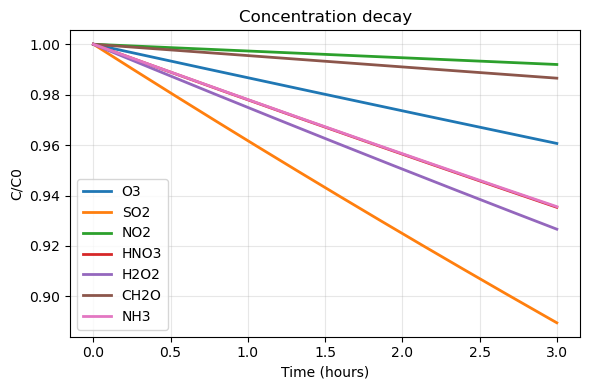

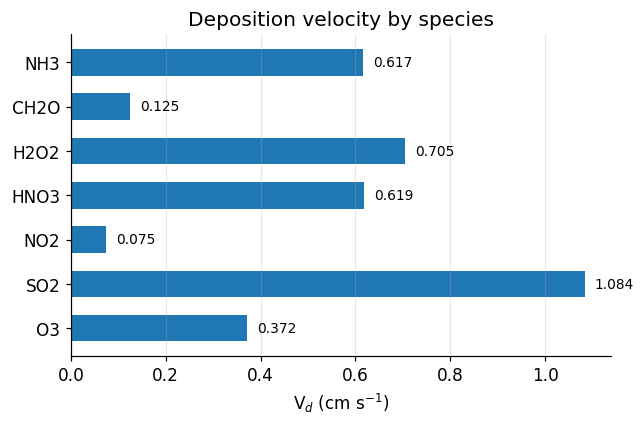

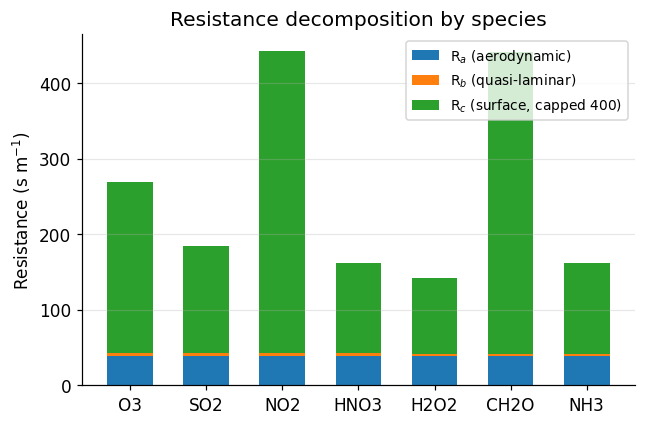

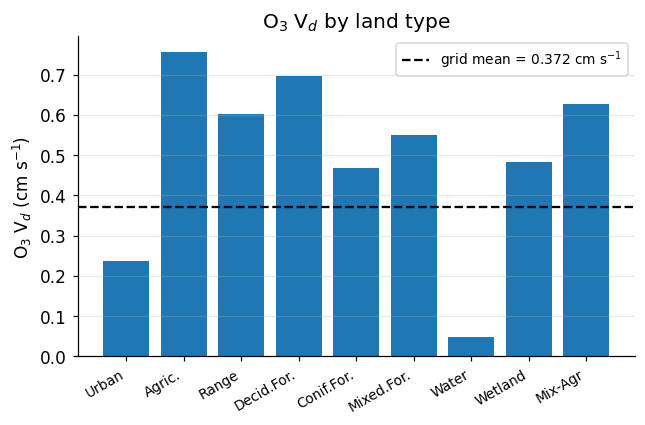

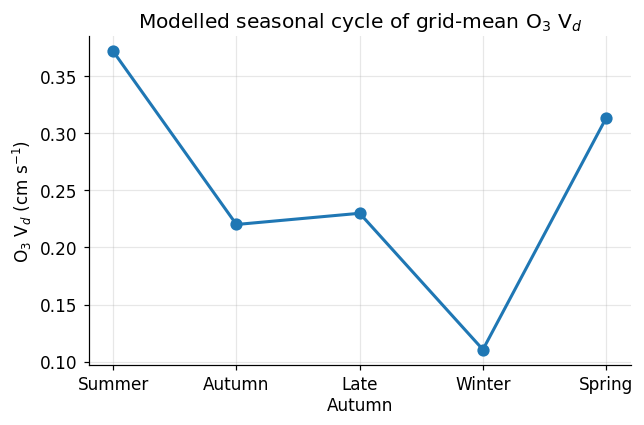

In [3]:
"""
All plots are model output from the Wesely (1989) scheme; no
external/literature values are included. Each figure is written as a
separate file. The only reference drawn is the model's own area-weighted
grid mean (in the O3-by-land-type plot).
"""

import numpy as np
import matplotlib.pyplot as plt




fig, ax = plt.subplots(figsize=(6, 4))
for sp in species_list:
    ax.plot(out['times']/3600, out['concs'][sp], lw=2, label=sp)
ax.set_xlabel('Time (hours)')
ax.set_ylabel('C/C0')
ax.set_title('Concentration decay')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

REF = "k"   # model grid-mean ref line

# Wesely (1989) land categories, in canonical index order.
LAND_NAMES = ["Urban", "Agric.", "Range", "Decid.For.", "Conif.For.",
              "Mixed.For.", "Water", "Desert", "Wetland", "Mix-Agr", "Rocky"]


vd  = [out["Vd"][sp] for sp in species_list]             # cm/s
ra  = [out["results"][sp]["Ra"] for sp in species_list]    # s/m
rb  = [out["results"][sp]["Rb"] for sp in species_list]
rc  = [out["results"][sp]["Rc"] for sp in species_list]

# Rc can run to very large values (near-inert species). cap for display only.
RC_DISPLAY_CAP = 400
rc_disp = [min(r, RC_DISPLAY_CAP) for r in rc]

# Per-land-type O3 deposition velocity from the resistance sum, cm/s.
# and NaN where the land type is absent so it doesn't plot as a misleading zero bar.
o3 = out["results"]["O3"]
vd_land = np.full(len(LAND_NAMES), np.nan)
for i in range(len(LAND_NAMES)):
    r_tot = o3["ra_lt"][i] + o3["rb_lt"][i] + o3["rc_lt"][i]
    if frac_landuse[i] > 0 and r_tot > 0:
        vd_land[i] = 100.0 / r_tot   # 1/R in m/s -> cm/s
present = [i for i in range(len(LAND_NAMES)) if frac_landuse[i] > 0]


# Vd by species 
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(species_list, vd, height=0.6, color="C0")
for y, v in enumerate(vd):
    ax.text(v + 0.02, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("V$_d$ (cm s$^{-1}$)")
ax.set_title("Deposition velocity by species")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("fig_vd_by_species.png")


# resistance decomposition 
# Series resistances add: Vd = 1/(Ra + Rb + Rc)
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(species_list))
ax.bar(x, ra, 0.6, label="R$_a$ (aerodynamic)", color="C0")
ax.bar(x, rb, 0.6, bottom=ra, label="R$_b$ (quasi-laminar)", color="C1")
ax.bar(x, rc_disp, 0.6, bottom=np.add(ra, rb),
       label=f"R$_c$ (surface, capped {RC_DISPLAY_CAP})", color="C2")
ax.set_xticks(x); ax.set_xticklabels(species_list)
ax.set_ylabel("Resistance (s m$^{-1}$)")
ax.set_title("Resistance decomposition by species")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("fig_resistances.png")


# O3 Vd by land type 
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(range(len(present)), vd_land[present], color="C0")
ax.axhline(out["Vd"]["O3"], color=REF, ls="--", lw=1.5,
           label=f"grid mean = {out['Vd']['O3']:.3f} cm s$^{{-1}}$")
ax.set_xticks(range(len(present)))
ax.set_xticklabels([LAND_NAMES[i] for i in present], rotation=30, ha="right", fontsize=9)
ax.set_ylabel("O$_3$ V$_d$ (cm s$^{-1}$)")
ax.set_title("O$_3$ V$_d$ by land type")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("fig_o3_vd_by_landtype.png")


# modelled seasonal cycle of grid-mean O3 Vd 
# Full frac_landuse is passed, so this is the grid-mean seasonal cycle,
# not a single land type. Model output only; no external reference.
season_month = {"Summer": 7, "Autumn": 10, "Late\nAutumn": 11,
                "Winter": 1, "Spring": 4}
met_no_month = {k: v for k, v in MET.items() if k != "month"}
vd_season = [wesely_gas("O3", frac_landuse=frac_landuse, month=m, **met_no_month)["Vd"]
             for m in season_month.values()]

fig, ax = plt.subplots(figsize=(6, 4))
xs = np.arange(len(season_month))
ax.plot(xs, vd_season, "o-", color="C0", lw=2, ms=7)
ax.set_xticks(xs); ax.set_xticklabels(list(season_month.keys()))
ax.set_ylabel("O$_3$ V$_d$ (cm s$^{-1}$)")
ax.set_title("Modelled seasonal cycle of grid-mean O$_3$ V$_d$")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fig_o3_seasonal.png")

plt.show()